# D02. Tiền xử lý giao dịch thẻ cho DBSCAN

*Dữ liệu mô phỏng (không phải dữ liệu ngân hàng thật). Chỉ import từ `src/` cùng pandas, numpy, matplotlib; sklearn chỉ xuất hiện ở ô kiểm tra chéo với StandardScaler và ở các ô đo ARI (DBSCAN tham chiếu trong `baseline/`: mục 3b, 9, 12).*

**Quyết định về D0.** D0 của quy trình trên file `card_txn_5d.csv` là **500 giao dịch sớm nhất theo timestamp**. Các file `card_stream/d0.csv` và `card_stream_hard/d0.csv` là những điểm sinh riêng: không dòng nào trùng với file thẻ trên năm cột nền và chúng không có `txn_id`, nên không dùng được làm danh sách id của D0. Mọi tham số học từ dữ liệu (trung vị điền khuyết, mean và std của ManualScaler) chỉ tính trên D0 này, rồi áp nguyên cho các dòng còn lại; không đọc `data/truth` khi làm sạch.

**Hai nguồn chuẩn hóa, đừng nhầm.** (1) `ManualScaler.fit` trên D0 (mục 6): không dùng thông tin tương lai. (2) Hằng số `frozen_scaling` trong `params.json` của stream (mục 7 và 9): do generator tính trên TOÀN BỘ bảng sạch (cả các dòng chưa xuất hiện và 15 hoặc 16 giao dịch bất thường), nên đây là một **cửa sổ tham chiếu cố định có chứa thông tin từ tương lai**, không phải fit trên D0. Hằng số này không sinh lại vì đã bị đóng băng; đo đánh đổi ở mục 9 và khuyến nghị cho báo cáo ở cuối mục đó.

---
#### **0. THƯ VIỆN VÀ ĐƯỜNG DẪN**

In [1]:
## Thư viện (sklearn không import ở đây) và thư mục gốc repo
import os
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def repo_root(start=None):
    """Thư mục gốc repo: đi ngược từ thư mục hiện tại đến nơi có src/preprocessing (chạy từ gốc repo hay từ notebooks/ đều được)."""
    here = Path(start or Path.cwd()).resolve()
    for d in (here, *here.parents):
        if (d / 'src' / 'preprocessing').is_dir():
            return d
    raise FileNotFoundError('không thấy src/preprocessing: hãy mở notebook bên trong repo')


def read_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))


ROOT = repo_root()
os.chdir(ROOT)      # từ đây mọi đường dẫn tương đối tính từ gốc repo; các import src/ và baseline/ tìm theo thư mục hiện tại
from src.preprocessing.cleaning import (NUMERIC_COLS, FEATURE_COLS, add_log_amount, clean_card_table, drop_exact_duplicates,
                                        fill_missing_category, fit_group_medians, fit_medians, flag_invalid_districts,
                                        flag_unknown_customers, impute_group_median, normalise_channel, parse_timestamp,
                                        quality_report, repair_hour_of_day, select_d0)
from src.preprocessing.scaler import ManualScaler
from src.preprocessing.scorecard import score_cleaning
from src.preprocessing.stream_scaling import apply_frozen_scaling
pd.set_option('display.max_columns', None); pd.set_option('display.width', 200)

In [2]:
## Thư mục dữ liệu (tương đối so với gốc repo)
RAW = 'data/raw/bank_card/'
OUT = 'data/processed/'
print(RAW, OUT)

data/raw/bank_card/ data/processed/


---
#### **1. ĐỌC DỮ LIỆU THÔ**

In [3]:
## Đọc bảng giao dịch thẻ thô
raw = pd.read_csv(RAW + 'card_txn_5d.csv')
raw.head()

,txn_id,amount_vnd,hour_of_day,distance_from_home_km,txns_last_7d,merchant_risk_score,segment_id,timestamp,customer_id,channel,merchant_category,txn_district_id,is_foreign
0,TXN001280,173000.0,13.23,6.29,8.0,0.201,0,2025-03-06 13:13:48,C0260,CONTACTLESS,ENT,D08,0
1,TXN001099,655000.0,22.95,0.12,4.0,0.319,1,2025-03-20 22:57:00,C0422,ONLINE,ECO,D06,0
2,TXN000267,213000.0,12.67,2.60,7.0,0.075,0,2025-03-30 12:40:12,C0409,CONTACTLESS,DIN,D06,0
3,TXN000506,33000.0,1.18,6.76,15.0,0.650,3,2025-03-15 01:10:48,C0004,ATM,ATM,D01,0
4,TXN001297,41000.0,2.72,7.03,15.0,0.697,3,2025-03-30 02:43:12,C0281,ATM,ATM,D02,0


In [4]:
## Kiểu dữ liệu và số ô thiếu
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 13 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   txn_id                 1500 non-null   object 
 1   amount_vnd             1477 non-null   float64
 2   hour_of_day            1478 non-null   float64
 3   distance_from_home_km  1482 non-null   float64
 4   txns_last_7d           1469 non-null   float64
 5   merchant_risk_score    1482 non-null   float64
 6   segment_id             1500 non-null   int64  
 7   timestamp              1500 non-null   object 
 8   customer_id            1500 non-null   object 
 9   channel                1500 non-null   object 
 10  merchant_category      1482 non-null   object 
 11  txn_district_id        1458 non-null   object 
 12  is_foreign             1500 non-null   int64  
dtypes: float64(5), int64(2), object(6)
memory usage: 152.5+ KB


In [5]:
## Đọc ba bảng chiều: khách hàng, nhóm merchant, quận
customers = pd.read_csv(RAW + 'customers.csv')
categories = pd.read_csv(RAW + 'merchant_categories.csv')
districts = pd.read_csv('data/raw/bank_geo/districts.csv')
print(customers.shape, categories.shape, districts.shape)
customers.head(3)

(600, 11) (14, 4) (8, 7)


,customer_id,age,gender,occupation_group,tier,tenure_months,monthly_income_vnd,home_district_id,digital_active,has_credit_card,preferred_channel
0,C0001,34,M,freelancer,mass,55,13700000,D08,1,1,mobile_app
1,C0002,36,M,other,mass,22,7900000,D07,1,0,mobile_app
2,C0003,24,F,trader,affluent,15,53000000,D03,1,0,mobile_app


---
#### **2. BÁO CÁO CHẤT LƯỢNG**

In [6]:
## Đếm từng loại lỗi (khớp danh mục lỗi trong data card)
quality_report(raw, customers, districts)

,check,column,n_rows,share
0,missing_value,amount_vnd,23,0.0153
1,missing_value,hour_of_day,22,0.0147
2,missing_value,distance_from_home_km,18,0.0120
3,missing_value,txns_last_7d,31,0.0207
4,missing_value,merchant_risk_score,18,0.0120
5,duplicate_row_exact_copy,(whole row),8,0.0053
6,duplicate_txn_id,txn_id,8,0.0053
7,inconsistent_spelling_or_case,channel,104,0.0693
8,mixed_timestamp_format_dd_mm_yyyy,timestamp,30,0.0200
9,impossible_timestamp,timestamp,6,0.0040


In [7]:
## Các giá trị khác nhau của cột channel (16 cách viết cho 4 kênh)
raw['channel'].value_counts()

channel
ONLINE          454
POS             419
ATM             270
CONTACTLESS     253
ONLINE           13
online           12
Pos              10
Online           10
contactless       9
 POS              9
pos               8
pos               8
contact-less      8
Atm               7
Contactless       5
atm               5
Name: count, dtype: int64

---
#### **3. EDA NGẮN (NỐI BẢNG KHÁCH HÀNG VÀ NHÓM MERCHANT)**

In [8]:
## Nối khách hàng và nhóm merchant (left join, khách lạ cho giá trị rỗng)
eda = raw.merge(customers, on='customer_id', how='left').merge(categories, left_on='merchant_category', right_on='category_code', how='left')
print(eda.shape, '| dòng không nối được khách:', eda['tier'].isna().sum(), '| không nối được nhóm hàng:', eda['name_en'].isna().sum())

(1500, 27) | dòng không nối được khách: 18 | không nối được nhóm hàng: 18


In [9]:
## Số tiền trung vị theo hạng khách (mass, affluent, ...)
eda.groupby('tier')['amount_vnd'].agg(['count', 'median']).sort_values('median')

,count,median
tier,,
mass,1010,239000.0
affluent,388,282500.0
priority,62,742500.0


In [10]:
## Giao dịch theo nhóm merchant và mức rủi ro cơ sở
eda.groupby(['base_risk_level', 'name_en']).size().rename('n').reset_index().sort_values('n', ascending=False).head(8)

,base_risk_level,name_en,n
0,high,cash_atm,279
6,low,grocery,209
10,medium,ecommerce,205
3,low,dining,191
13,medium,travel_lodging,173
12,medium,fashion_retail,110
11,medium,entertainment,83
4,low,education,55


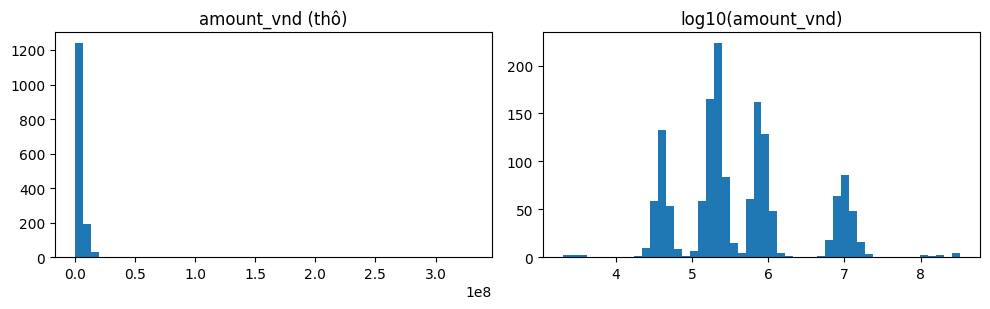

In [11]:
## Số tiền trải bốn bậc độ lớn: biểu đồ histogram trước và sau log10
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].hist(raw['amount_vnd'].dropna(), bins=50); ax[0].set_title('amount_vnd (thô)')
ax[1].hist(np.log10(raw['amount_vnd'].dropna()), bins=50); ax[1].set_title('log10(amount_vnd)')
plt.tight_layout(); plt.show()

#### **3b. log10 CỦA SỐ TIỀN: ĐO THỰC TẾ**

Số tiền lệch phải rất mạnh nên log10 là lựa chọn thiết kế hợp lý. Ô dưới đo xem nó có THẬT SỰ cần không: chọn Eps và MinPts tốt nhất trên một lưới (có dùng nhãn thật nên là cận trên, như bảng ba mức trong data card), với ba cách chuẩn hóa, trên cả hai file thẻ. Cách tham chiếu của generator: bỏ dòng thiếu ô và dòng trùng.

In [12]:
## Độ lệch (skewness) của số tiền trước và sau log10
amt = raw['amount_vnd'].dropna()
print('skewness amount_vnd:', round(amt.skew(), 2), '| log10(amount_vnd):', round(np.log10(amt).skew(), 2))

skewness amount_vnd: 14.05 | log10(amount_vnd): 0.61


In [13]:
## ARI của DBSCAN (nhiễu tính một lớp) với ba cách chuẩn hóa, hai file thẻ
from baseline.sklearn_dbscan import fit_full_dbscan, compare_partitions


def best_on_grid(Z, y, eps_grid, minpts_grid=(4, 6, 8, 10, 12, 15)):
    best = (-1.0, None)
    for e in eps_grid:
        for m in minpts_grid:
            a = compare_partitions(fit_full_dbscan(Z, e, m)[0], y)['ari']
            if a > best[0]:
                best = (a, (round(float(e), 2), m))
    return best


rows = []
for name, fixed in (('card_txn_5d', (0.65, 10)), ('card_txn_5d_hard', (0.30, 15))):
    r = pd.read_csv(RAW + name + '.csv').drop_duplicates().dropna(subset=NUMERIC_COLS)
    y = pd.read_csv(f'data/truth/{name}_clean_base.csv').set_index('txn_id')['segment_id'].reindex(r['txn_id']).to_numpy()   # đáp án chỉ để chấm
    X = r[NUMERIC_COLS].to_numpy(float); XL = X.copy(); XL[:, 0] = np.log10(XL[:, 0])
    for label, Z, grid in (('log10 + z-score', ManualScaler().fit_transform(XL), np.arange(0.2, 1.501, 0.05)),
                           ('z-score, không log10', ManualScaler().fit_transform(X), np.arange(0.2, 1.501, 0.05)),
                           ('log10, không z-score', XL, np.arange(0.2, 3.001, 0.1))):
        a, (e, m) = best_on_grid(Z, y, grid)
        a_fixed = compare_partitions(fit_full_dbscan(Z, *fixed)[0], y)['ari']
        rows.append((name, label, len(r), round(a, 4), f'Eps {e}, MinPts {m}', round(a_fixed, 4)))
pd.DataFrame(rows, columns=['file', 'chuẩn hóa', 'n dòng', 'ARI tốt nhất trên lưới', 'tham số tốt nhất',
                            'ARI tại Eps, MinPts cố định (dễ 0.65 và 10, khó 0.30 và 15)'])

,file,chuẩn hóa,n dòng,ARI tốt nhất trên lưới,tham số tốt nhất,"ARI tại Eps, MinPts cố định (dễ 0.65 và 10, khó 0.30 và 15)"
0,card_txn_5d,log10 + z-score,1383,1.0000,"Eps 0.45, MinPts 4",1.0000
1,card_txn_5d,"z-score, không log10",1383,1.0000,"Eps 0.45, MinPts 4",1.0000
2,card_txn_5d,"log10, không z-score",1383,0.9970,"Eps 2.8, MinPts 4",0.0788
3,card_txn_5d_hard,log10 + z-score,1475,0.6463,"Eps 0.3, MinPts 15",0.6463
4,card_txn_5d_hard,"z-score, không log10",1475,0.5520,"Eps 0.4, MinPts 15",0.5010
5,card_txn_5d_hard,"log10, không z-score",1475,0.5535,"Eps 2.8, MinPts 4",0.0000


**Kết luận đo được.** (1) File thẻ DỄ: bỏ log10 vẫn đạt ARI 1.0 (cả ở tham số tốt nhất lẫn ở Eps 0.65, MinPts 10 của file), nên câu "không log10 thì DBSCAN thất bại" từng viết trong data card và trong docstring của `add_log_amount` là SAI và đã sửa. (2) File thẻ KHÓ: log10 có lợi đo được, ARI 0.646 so với 0.552 (tại Eps 0.30, MinPts 15: 0.646 so với 0.501). (3) Bước quyết định là z-score: log10 mà không z-score cho ARI 0.079 ở Eps 0.65 (các cột khác đơn vị nên một Eps duy nhất vô nghĩa) và phải đưa Eps lên 2.8 mới đạt 0.997 ở file dễ. Vậy trong báo cáo nên nói: số tiền lệch phải nên dùng log10 (có lợi ở bản khó, không bắt buộc ở bản dễ), còn z-score là bắt buộc. Tham số ở bảng chọn bằng nhãn thật nên là cận trên, không phải điều nhóm đạt được khi không biết nhãn.

---
#### **4. LÀM SẠCH TỪNG BƯỚC**

In [14]:
## Bước 1: bỏ bản sao y hệt (chỉ dòng trùng mọi cột)
df = drop_exact_duplicates(raw)
print(len(raw), '->', len(df), '| txn_id duy nhất:', df['txn_id'].is_unique)

1500 -> 1492 | txn_id duy nhất: True


In [15]:
## Bước 2: chuẩn hóa kênh (strip, hoa, bỏ gạch nối)
df['channel'] = normalise_channel(df['channel'])
df['channel'].value_counts(dropna=False)

channel
ONLINE         486
POS            451
ATM            281
CONTACTLESS    274
Name: count, dtype: int64

In [16]:
## Bước 3: đọc timestamp (ISO, dd/mm/yyyy, giá trị vô lý bị gắn cờ)
df = pd.concat([df, parse_timestamp(df['timestamp'])], axis=1)
print(df['ts_status'].value_counts().to_dict())
df[df['ts_status'] != 'iso'][['txn_id', 'timestamp', 'ts', 'ts_status']].head(8)

{'iso': 1456, 'dmy': 30, 'impossible': 6}


,txn_id,timestamp,ts,ts_status
42,TXN001488,21/04/2025 17:51:36,2025-04-21 17:51:36,dmy
56,TXN001008,23/04/2025 12:09:00,2025-04-23 12:09:00,dmy
151,TXN001300,15/03/2025 15:12:00,2025-03-15 15:12:00,dmy
167,TXN000941,20/04/2025 22:10:12,2025-04-20 22:10:12,dmy
226,TXN001183,03/04/2025 15:37:48,2025-04-03 15:37:48,dmy
293,TXN000144,25/03/2025 14:19:48,2025-03-25 14:19:48,dmy
317,TXN001058,09/03/2025 01:49:48,2025-03-09 01:49:48,dmy
400,TXN000576,23/04/2025 20:00:36,2025-04-23 20:00:36,dmy


In [17]:
## Bước 4: điền hour_of_day thiếu từ giờ của timestamp
n_thieu = df['hour_of_day'].isna().sum()
df = repair_hour_of_day(df)
print('thiếu trước:', n_thieu, '| còn thiếu:', df['hour_of_day'].isna().sum(), '| sửa từ timestamp:', df['hour_from_ts'].sum())

thiếu trước: 22 | còn thiếu: 0 | sửa từ timestamp: 22


In [18]:
## Bước 5: merchant_category thiếu thì điền UNKNOWN và gắn cờ
df = fill_missing_category(df)
print(df['category_missing'].sum(), 'dòng được gắn cờ')

18 dòng được gắn cờ


In [19]:
## Bước 6: D0 = 500 giao dịch sớm nhất theo timestamp (stream thẻ cũng dùng 500 điểm đầu)
df['is_d0'] = select_d0(df, 500)
print(df['is_d0'].sum(), 'dòng D0 | từ', df.loc[df['is_d0'], 'ts'].min(), 'đến', df.loc[df['is_d0'], 'ts'].max())

500 dòng D0 | từ 2025-03-01 01:34:12 đến 2025-03-20 16:06:00


In [20]:
## Bước 7a: trung vị chung của D0 (dùng làm phương án cuối của thứ bậc điền khuyết)
medians = fit_medians(df[df['is_d0']])
medians

{'amount_vnd': 240000.0,
 'hour_of_day': 13.22,
 'distance_from_home_km': 4.390000000000001,
 'txns_last_7d': 8.0,
 'merchant_risk_score': 0.3455}

In [21]:
## Bước 7b: trung vị theo nhóm trên D0, tầng 1 = (kênh x nhóm hàng), tầng 2 = kênh, bỏ nhóm dưới 5 dòng
group_med = fit_group_medians(df[df['is_d0']])
print('số nhóm giữ lại (tầng 1, tầng 2):', [int(t['txns_last_7d'].notna().sum()) for t in group_med])
group_med[1]

số nhóm giữ lại (tầng 1, tầng 2): [25, 4]


,amount_vnd,hour_of_day,distance_from_home_km,txns_last_7d,merchant_risk_score
channel,,,,,
ATM,41000.0,1.575,7.870,13.5,0.6420
CONTACTLESS,208000.0,12.610,4.925,9.0,0.1340
ONLINE,826000.0,20.530,1.160,4.0,0.3585
POS,220000.0,12.900,4.520,8.0,0.1415


In [22]:
## Bước 8: điền ô số thiếu theo thứ bậc (kênh x nhóm hàng, rồi kênh, rồi chung), gắn cờ imp_<cột>
thieu_truoc = df[NUMERIC_COLS].isna().sum()
df = impute_group_median(df, group_med, medians)
pd.DataFrame({'thiếu trước bước 8': thieu_truoc, 'thiếu sau': df[NUMERIC_COLS].isna().sum(), 'số ô được điền': df[['imp_' + c for c in NUMERIC_COLS]].sum().values})

,thiếu trước bước 8,thiếu sau,số ô được điền
amount_vnd,23,0,23
hour_of_day,0,0,0
distance_from_home_km,18,0,18
txns_last_7d,31,0,31
merchant_risk_score,18,0,18


In [23]:
## Bước 9: gắn cờ khách lạ và mã quận sai (không xóa dòng)
df['unknown_customer'] = flag_unknown_customers(df, customers)
df['invalid_district'] = flag_invalid_districts(df, districts)
print('khách lạ:', df['unknown_customer'].sum(), '| quận sai:', df['invalid_district'].sum())

khách lạ: 18 | quận sai: 5


In [24]:
## Bước 10: thêm log10 của số tiền
df = add_log_amount(df)
df[['amount_vnd', 'log10_amount_vnd']].describe().T

,count,mean,std,min,25%,50%,75%,max
amount_vnd,1492.0,3.275367e+06,1.859641e+07,2000.00000,162000.000000,250000.00000,887000.000000,3.302870e+08
log10_amount_vnd,1492.0,5.622314e+00,7.861197e-01,3.30103,5.209515,5.39794,5.947924,8.518891e+00


In [25]:
## Không loại ngoại lai bằng IQR: thử đếm xem quy tắc IQR sẽ xóa gì
q1, q3 = df[FEATURE_COLS].quantile(0.25), df[FEATURE_COLS].quantile(0.75)
ngoai_lai = ((df[FEATURE_COLS] < q1 - 1.5 * (q3 - q1)) | (df[FEATURE_COLS] > q3 + 1.5 * (q3 - q1))).any(axis=1)
bat_thuong = df['txn_id'].isin(raw.loc[raw['segment_id'] == -1, 'txn_id'])
print('IQR sẽ xóa', ngoai_lai.sum(), 'dòng =', round(100 * ngoai_lai.mean(), 1), '%; trong đó bất thường thật:', (ngoai_lai & bat_thuong).sum(), '/', bat_thuong.sum())
print('=> giữ nguyên: với DBSCAN, ngoại lai chính là nhiễu cần phát hiện')

IQR sẽ xóa 251 dòng = 16.8 %; trong đó bất thường thật: 15 / 15
=> giữ nguyên: với DBSCAN, ngoại lai chính là nhiễu cần phát hiện


In [26]:
## Kiểm tra: các bước trên khớp hàm gộp clean_card_table (mặc định điền theo nhóm)
clean, med_d0 = clean_card_table(raw, customers, districts)
cot = ['txn_id'] + FEATURE_COLS
print('khớp từng ô:', df[cot].reset_index(drop=True).equals(clean[cot].reset_index(drop=True)), '| số dòng sạch:', len(clean))

khớp từng ô: True | số dòng sạch: 1492


In [27]:
## Phương án đơn giản để so sánh: chỉ điền trung vị chung của D0 (impute_by=None)
clean_g, med_g = clean_card_table(raw, customers, districts, impute_by=None)
print('giá trị điền khác nhau ở', int((clean_g[NUMERIC_COLS].to_numpy() != clean[NUMERIC_COLS].to_numpy()).sum()), 'ô')

giá trị điền khác nhau ở 88 ô


---
#### **5. PHÂN PHỐI TRƯỚC VÀ SAU LÀM SẠCH**

In [28]:
## Thống kê mô tả trước (thô) và sau làm sạch cho năm đặc trưng
truoc = raw[NUMERIC_COLS].describe().T[['count', 'mean', '50%', 'std']]
sau = clean[FEATURE_COLS].describe().T[['count', 'mean', '50%', 'std']]
pd.concat([truoc, sau], axis=1, keys=['thô', 'sạch'])

thô                                            sạch                                
                        count          mean         50%           std   count       mean       50%        std
amount_vnd             1477.0  3.304975e+06  250000.000  1.868849e+07     NaN        NaN       NaN        NaN
hour_of_day            1478.0  1.323499e+01      13.385  6.715688e+00  1492.0  13.273405  13.42500   6.682262
distance_from_home_km  1482.0  1.747062e+01       4.210  5.482779e+01  1492.0  17.345593   4.22000  54.650712
txns_last_7d           1469.0  7.566372e+00       8.000  5.376479e+00  1492.0   7.568700   8.00000   5.357489
merchant_risk_score    1482.0  3.376667e-01       0.344  2.044101e-01  1492.0   0.337027   0.34400   0.204248
log10_amount_vnd          NaN           NaN         NaN           NaN  1492.0   5.622314   5.39794   0.786120

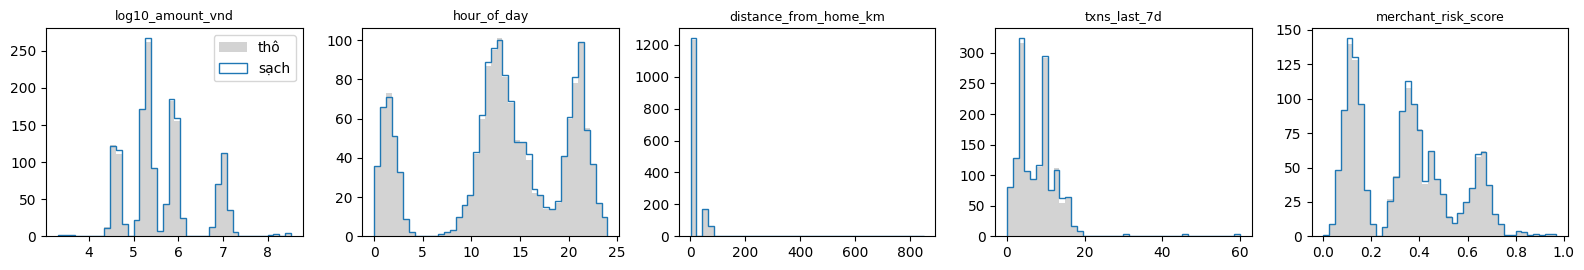

In [29]:
## Histogram năm đặc trưng: thô (xám) và sau làm sạch (xanh)
fig, ax = plt.subplots(1, 5, figsize=(16, 2.8))
for a, c_raw, c_new in zip(ax, NUMERIC_COLS, FEATURE_COLS):
    v = np.log10(raw[c_raw].dropna()) if c_raw == 'amount_vnd' else raw[c_raw].dropna()
    a.hist(v, bins=40, color='lightgray', label='thô'); a.hist(clean[c_new], bins=40, histtype='step', color='tab:blue', label='sạch'); a.set_title(c_new, fontsize=9)
ax[0].legend(); plt.tight_layout(); plt.show()

---
#### **6. CHUẨN HÓA BẰNG ManualScaler (CHỈ FIT TRÊN D0)**

In [30]:
## Fit ManualScaler trên D0 (population std, ddof = 0)
scaler = ManualScaler('standard').fit(clean.loc[clean['is_d0'], FEATURE_COLS])
pd.DataFrame({'mean': scaler.center_, 'std': scaler.scale_}, index=FEATURE_COLS)

,mean,std
log10_amount_vnd,5.588217,0.789180
hour_of_day,12.913020,6.749424
distance_from_home_km,17.720200,56.552827
txns_last_7d,7.772000,5.580145
merchant_risk_score,0.340574,0.211632


In [31]:
## Biến đổi mọi dòng bằng tham số của D0 (không fit lại)
z = scaler.transform(clean[FEATURE_COLS])
scaled = pd.DataFrame(z, columns=[c + '_z' for c in FEATURE_COLS])
scaled.insert(0, 'txn_id', clean['txn_id'].values)
print('D0: mean', scaled.loc[clean['is_d0'].values].iloc[:, 1:].mean().round(3).tolist())
print('D0: std ', scaled.loc[clean['is_d0'].values].iloc[:, 1:].std(ddof=0).round(3).tolist())
print('toàn bộ: mean', scaled.iloc[:, 1:].mean().round(3).tolist())

D0: mean [0.0, -0.0, 0.0, -0.0, 0.0]
D0: std  [1.0, 1.0, 1.0, 1.0, 1.0]
toàn bộ: mean [0.043, 0.053, -0.007, -0.036, -0.017]


In [32]:
## Kiểm tra chéo với StandardScaler của sklearn (ô duy nhất dùng sklearn)
from sklearn.preprocessing import StandardScaler
sk = StandardScaler().fit(clean.loc[clean['is_d0'], FEATURE_COLS])
print('sai khác lớn nhất:', np.abs(sk.transform(clean[FEATURE_COLS]) - z).max())

sai khác lớn nhất: 0.0


In [33]:
## Điểm mới đi qua cùng tham số: một giao dịch mới 5 triệu, 14 giờ, 3 km, 6 lần, rủi ro 0.2
moi = np.array([np.log10(5_000_000), 14.0, 3.0, 6, 0.2])
print(scaler.transform(moi).round(3), '| tham số không đổi:', np.allclose(scaler.center_, sk.mean_))

[ 1.407  0.161 -0.26  -0.318 -0.664] | tham số không đổi: True


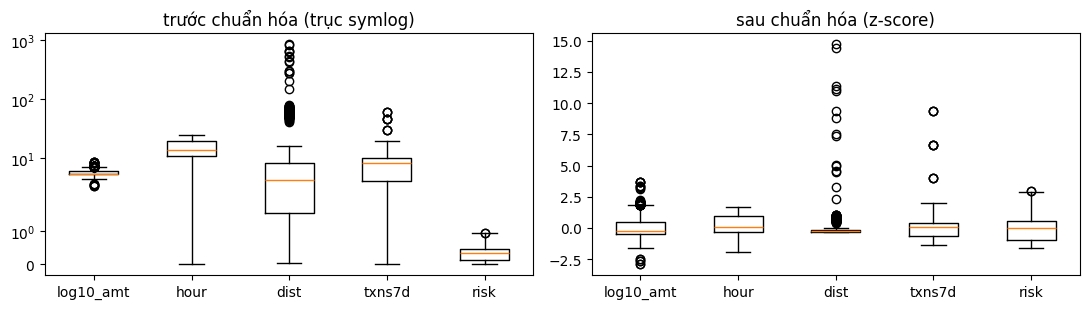

In [34]:
## Boxplot năm đặc trưng trước (log10 amount, đơn vị gốc) và sau chuẩn hóa
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].boxplot([clean[c] for c in FEATURE_COLS], tick_labels=['log10_amt', 'hour', 'dist', 'txns7d', 'risk']); ax[0].set_yscale('symlog'); ax[0].set_title('trước chuẩn hóa (trục symlog)')
ax[1].boxplot([scaled[c + '_z'] for c in FEATURE_COLS], tick_labels=['log10_amt', 'hour', 'dist', 'txns7d', 'risk']); ax[1].set_title('sau chuẩn hóa (z-score)')
plt.tight_layout(); plt.show()

---
#### **7. SO SÁNH VỚI frozen_scaling CỦA STREAM THẺ (CỬA SỔ THAM CHIẾU CỐ ĐỊNH)**

In [35]:
## Đọc hằng số cố định của card_stream, và bản fit trên bảng đáp án chưa bị đục ô (chỉ để kiểm chứng công thức)
fs = read_json(RAW + 'card_stream/params.json')['frozen_scaling']
tb = pd.read_csv('data/truth/card_txn_5d_clean_base.csv')
y = tb[NUMERIC_COLS].copy(); y['amount_vnd'] = np.log10(y['amount_vnd'])
fit_all = ManualScaler().fit(clean[FEATURE_COLS])
fit_truth = ManualScaler().fit(y)
def lech(sc): return max(np.abs(sc.center_ - fs['mean']).max(), np.abs(sc.scale_ - fs['std']).max())
print('sai lệch lớn nhất so với frozen_scaling (mean và std):')
print('  fit trên D0 đã làm sạch   :', lech(scaler))
print('  fit trên mọi dòng đã sạch :', lech(fit_all))
print('  fit trên bảng đáp án      :', lech(fit_truth))

sai lệch lớn nhất so với frozen_scaling (mean và std):
  fit trên D0 đã làm sạch   : 1.9215553597690231
  fit trên mọi dòng đã sạch : 0.014558758634102276
  fit trên bảng đáp án      : 1.7763568394002505e-14


In [36]:
## Bảng từng cột: frozen, D0, mọi dòng sạch (mean rồi std)
pd.DataFrame({'mean frozen': fs['mean'], 'mean D0': scaler.center_, 'mean all': fit_all.center_, 'std frozen': fs['std'], 'std D0': scaler.scale_, 'std all': fit_all.scale_}, index=FEATURE_COLS).round(4)

,mean frozen,mean D0,mean all,std frozen,std D0,std all
log10_amount_vnd,5.6223,5.5882,5.6223,0.7856,0.7892,0.7859
hour_of_day,13.2734,12.9130,13.2734,6.6800,6.7494,6.6800
distance_from_home_km,17.3386,17.7202,17.3456,54.6313,56.5528,54.6324
txns_last_7d,7.5650,7.7720,7.5687,5.3703,5.5801,5.3557
merchant_risk_score,0.3378,0.3406,0.3370,0.2045,0.2116,0.2042


**Kết luận ô trên.** Hằng số `frozen_scaling` là một **cửa sổ tham chiếu cố định**: generator tính trên toàn bộ bảng đáp án (mọi 1492 dòng, trước khi đục ô thiếu), tức là gồm cả các dòng chỉ xuất hiện về sau trong stream và 15 giao dịch bất thường, nên nó chứa thông tin từ TƯƠNG LAI so với D0 và KHÔNG phải fit trên D0 (quy tắc "chỉ fit trên D0" của mục 6 không áp dụng cho nó). Nó không sinh lại vì đã bị đóng băng trong `data/base_hashes.json`. Hệ quả: chỉ bản fit trên bảng đáp án trùng đến 1e-6 (khoảng 1e-14). Bản fit trên D0 lệch rõ ở `distance_from_home_km` (std 56.55 so với 54.63) vì D0 chỉ là mẫu 500 dòng và std cột này do vài giao dịch bất thường xa 470 km quyết định (D0 có 5 giao dịch như vậy), nên dao động mẫu lớn; bản fit trên mọi dòng sạch lệch nhỏ do điền trung vị làm std co lại. `hour_of_day` của bản fit trên mọi dòng sạch trùng hoàn toàn vì giờ khôi phục chính xác từ timestamp. Stream thẻ (`card_stream/d0.csv`) là các điểm sinh riêng, không phải dòng của file này nên không có txn_id để khớp; D0 ở đây là 500 giao dịch sớm nhất.

In [37]:
## Hàm dùng chung cho stream (baseline/ và src/experiments/ sau này gọi đúng hàm này): tọa độ của d0 stream thẻ
params_stream = read_json(RAW + 'card_stream/params.json')
z_d0 = apply_frozen_scaling(params_stream, pd.read_csv(RAW + 'card_stream/d0.csv'))
print('3 điểm đầu của d0 (z):'); print(z_d0[:3].round(3))
print('trung bình z của d0:', z_d0.mean(axis=0).round(3), '(khác 0 vì hằng số lấy từ cửa sổ tham chiếu, không phải từ D0)')

3 điểm đầu của d0 (z):
[[ 0.37   1.308 -0.301 -0.664  0.162]
 [-0.351 -0.12  -0.261  0.081 -1.104]
 [ 0.362  1.296 -0.302 -0.478 -0.019]]
trung bình z của d0: [ 0.274  0.371  0.037 -0.25  -0.331] (khác 0 vì hằng số lấy từ cửa sổ tham chiếu, không phải từ D0)


---
#### **8. K-DISTANCE: CHỌN Eps VÀ MinPts**

In [38]:
## Tham số tham chiếu của nhóm (bank_card/params.json cho bảng 1500 dòng, card_stream/params.json cho cửa sổ 500 điểm)
p_file = read_json(RAW + 'params.json'); p_stream = read_json(RAW + 'card_stream/params.json')
print('bảng thẻ: Eps', p_file['recommended_eps'], 'MinPts', p_file['recommended_minpts'], '| stream: Eps', p_stream['eps'], 'MinPts', p_stream['minpts'])

bảng thẻ: Eps 0.65 MinPts 10 | stream: Eps 0.4 MinPts 6


In [39]:
## Khoảng cách tới láng giềng thứ k (tính cả chính điểm) bằng numpy, không dùng thư viện
def k_distance(zz, k):
    d = np.sqrt(((zz[:, None, :] - zz[None, :, :]) ** 2).sum(axis=2))
    return np.sort(d, axis=1)[:, k - 1]
print(k_distance(np.array([[0., 0.], [3., 4.], [6., 8.]]), 2))

[5. 5. 5.]


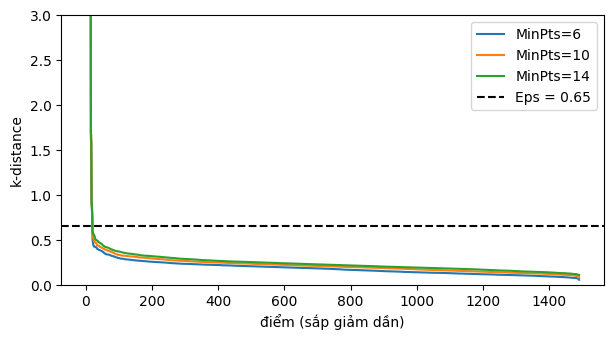

In [40]:
## Đồ thị k-distance cho MinPts = 6, 10, 14 trên mọi dòng đã chuẩn hóa, kèm Eps = 0.65
zz = scaled[[c + '_z' for c in FEATURE_COLS]].to_numpy()
plt.figure(figsize=(7, 3.5))
for k in (6, 10, 14):
    plt.plot(np.sort(k_distance(zz, k))[::-1], label=f'MinPts={k}')
plt.axhline(p_file['recommended_eps'], color='k', ls='--', label='Eps = 0.65'); plt.ylim(0, 3); plt.legend(); plt.xlabel('điểm (sắp giảm dần)'); plt.ylabel('k-distance'); plt.show()

In [41]:
## Với MinPts = 10 và Eps = 0.65: bao nhiêu điểm có k-distance không quá Eps (đủ điều kiện lõi) và bao nhiêu lớn hơn
kd = k_distance(zz, 10)
print('lõi:', (kd <= 0.65).sum(), '| còn lại (biên hoặc nhiễu):', (kd > 0.65).sum(), '| bất thường cài sẵn:', bat_thuong.sum())
print('phân vị 90/95/99 của k-distance:', np.percentile(kd, [90, 95, 99]).round(3))

lõi: 1472 | còn lại (biên hoặc nhiễu): 20 | bất thường cài sẵn: 15
phân vị 90/95/99 của k-distance: [0.311 0.367 1.926]


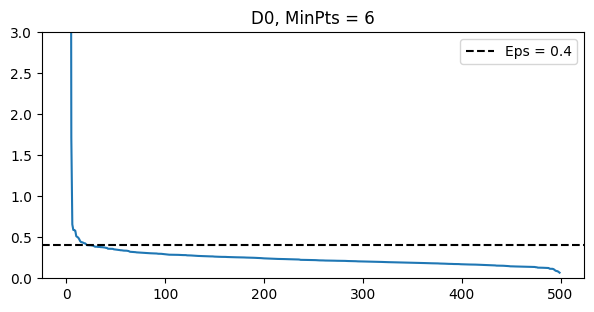

D0: điểm có k-distance <= 0.4: 474 / 500


In [42]:
## Cửa sổ stream: D0 500 điểm với MinPts = 6 và Eps = 0.4
z0 = zz[clean['is_d0'].to_numpy()]
kd0 = k_distance(z0, 6)
plt.figure(figsize=(7, 3.2)); plt.plot(np.sort(kd0)[::-1]); plt.axhline(p_stream['eps'], color='k', ls='--', label='Eps = 0.4'); plt.ylim(0, 3); plt.legend(); plt.title('D0, MinPts = 6'); plt.show()
print('D0: điểm có k-distance <= 0.4:', (kd0 <= 0.4).sum(), '/', len(kd0))

---
#### **9. ĐỘ BỀN VÀ RÒ RỈ THÔNG TIN TƯƠNG LAI: FIT TRÊN D0 SO VỚI CỬA SỔ THAM CHIẾU CỐ ĐỊNH**

In [43]:
## DBSCAN tham chiếu của nhóm (baseline/, dùng sklearn) và hai cách chuẩn hóa D0
from baseline.sklearn_dbscan import fit_full_dbscan, compare_partitions
frozen = ManualScaler.from_dict({'method': 'standard', 'center': fs['mean'], 'scale': fs['std']})
d0_mask = clean['is_d0'].to_numpy()
z_fit0, z_frozen0 = scaler.transform(clean.loc[d0_mask, FEATURE_COLS]), frozen.transform(clean.loc[d0_mask, FEATURE_COLS])
lab_fit, typ_fit = fit_full_dbscan(z_fit0, p_stream['eps'], p_stream['minpts'])
lab_frz, typ_frz = fit_full_dbscan(z_frozen0, p_stream['eps'], p_stream['minpts'])
pd.DataFrame({'fit trên D0': [lab_fit.max() + 1, (lab_fit == -1).sum(), (typ_fit == 3).sum()], 'frozen_scaling': [lab_frz.max() + 1, (lab_frz == -1).sum(), (typ_frz == 3).sum()]}, index=['số cụm', 'số nhiễu', 'số điểm lõi'])

,fit trên D0,frozen_scaling
số cụm,4,4
số nhiễu,10,11
số điểm lõi,474,471


In [44]:
## ARI giữa hai nhãn (nhiễu tính một lớp) và so tập nhiễu, tập lõi
r = compare_partitions(lab_fit, lab_frz, types_a=typ_fit, types_b=typ_frz)
print('ARI =', round(r['ari'], 4), '| tập nhiễu giống nhau:', r['noise_equal'], '| tập lõi giống nhau:', r['core_equal'])
print('nhiễu chỉ có ở fit-D0:', len(r['noise_only_a']), '| chỉ có ở frozen:', len(r['noise_only_b']), '| lõi chung:', int(((typ_fit == 3) & (typ_frz == 3)).sum()))

ARI = 0.9959 | tập nhiễu giống nhau: False | tập lõi giống nhau: False
nhiễu chỉ có ở fit-D0: 0 | chỉ có ở frozen: 1 | lõi chung: 471


In [45]:
## std của distance_from_home_km trên mẫu 500 dòng: thô so với log1p (lấy mẫu lại 500 lần từ mọi dòng sạch)
dist = clean['distance_from_home_km'].to_numpy(); rng = np.random.default_rng(0)
idx = [rng.integers(0, len(dist), 500) for _ in range(500)]
std_raw = np.array([dist[i].std() for i in idx]); std_log = np.array([np.log1p(dist[i]).std() for i in idx])
bat = (clean['segment_id'] == -1).to_numpy()
print('std thô: trung bình', std_raw.mean().round(1), '| khoảng 5-95%:', np.percentile(std_raw, [5, 95]).round(1), '| hệ số biến thiên', (std_raw.std() / std_raw.mean()).round(3))
print('std log1p: trung bình', std_log.mean().round(3), '| khoảng 5-95%:', np.percentile(std_log, [5, 95]).round(3), '| hệ số biến thiên', (std_log.std() / std_log.mean()).round(3))
print('D0: std thô', dist[d0_mask].std().round(1), '| bỏ giao dịch bất thường', dist[d0_mask & ~bat].std().round(1), '| số bất thường trong D0:', int((d0_mask & bat).sum()))

std thô: trung bình 52.5 | khoảng 5-95%: [29.9 75.4] | hệ số biến thiên 0.257
std log1p: trung bình 1.23 | khoảng 5-95%: [1.155 1.299] | hệ số biến thiên 0.036
D0: std thô 56.6 | bỏ giao dịch bất thường 20.7 | số bất thường trong D0: 5


**Đọc kết quả độ bền.** Ở bản dễ, chuẩn hóa fit trên D0 và hằng số `frozen_scaling` cho gần như cùng phân hoạch (4 cụm, ARI 0.996, 474 so với 471 điểm lõi), nhưng ở bản khó cùng Eps đã làm ARI tụt còn 0.887 và số lõi đổi từ 260 sang 240: một lệch nhỏ của mean và std là đủ đổi tập lõi. Nguyên nhân chính là `distance_from_home_km` có đuôi rất nặng: trong D0, 5 giao dịch bất thường xa khoảng 470 km quyết định gần hết std (56.6, còn 20.7 nếu bỏ 5 điểm đó), và lấy mẫu lại 500 dòng cho std từ 30 đến 75 (hệ số biến thiên 0.26), nên z-score fit trên mẫu 500 dòng dễ lệch. Phương án để cân nhắc khi báo cáo là biến đổi `log1p(distance_from_home_km)` trước khi chuẩn hóa (std dao động chỉ 0.036 theo hệ số biến thiên); các hằng số frozen_scaling của stream giữ nguyên, không đổi.

**Khuyến nghị cho báo cáo.** Hằng số `frozen_scaling` là cửa sổ tham chiếu cố định có chứa thông tin từ tương lai; fit trên D0 thì không, và hai cách cho kết quả khác nhau: ARI 0.9959 (474 so với 471 điểm lõi) ở stream thẻ dễ và 0.887 (260 so với 240 điểm lõi) ở stream thẻ khó, cùng Eps và MinPts, chỉ xét D0. (1) Phát lại stream bằng hằng số cố định (`apply_frozen_scaling`) để mọi thuật toán (re-fit, Incremental DBSCAN) thấy đúng cùng một tọa độ và so nhãn được công bằng. (2) Chỉ dùng fit trên D0 trong notebook này để minh họa đánh đổi rò rỉ thông tin tương lai, không dùng để chấm thuật toán. (3) Khi trình bày, gọi đúng tên: cửa sổ tham chiếu cố định, có thông tin từ tương lai, được chọn có chủ ý và kèm số đo ở trên.

---
#### **10. SCORECARD: SO VỚI ĐÁP ÁN**

In [46]:
## Đọc đáp án (chỉ dùng để chấm điểm, không dùng để sửa)
truth_base = pd.read_csv('data/truth/card_txn_5d_clean_base.csv'); truth_desc = pd.read_csv('data/truth/card_txn_5d_clean_descriptive.csv')
print(truth_base.shape, truth_desc.shape)

(1492, 7) (1492, 7)


In [47]:
## Chấm điểm từng loại lỗi
sc_easy = score_cleaning('card_txn_5d', raw, clean, truth_base, truth_desc, clean_g, med_g)
sc_easy.drop(columns='table')

,defect,column,n,metric,value,global_median_error,gain_x,note
0,duplicate_row_exact_copy,(whole row),8,share_removed,1.000000,NaN,NaN,"còn 1492 dòng, đáp án có 1492; txn_id duy nhất..."
1,missing_value,amount_vnd,23,median_abs_error,62000.000000,2.020000e+05,3.258065,trung vị theo (kênh x nhóm hàng) -> kênh -> ch...
2,missing_value,amount_vnd,23,mean_abs_error,107130.434783,1.077043e+06,10.053571,trung vị theo (kênh x nhóm hàng) -> kênh -> ch...
3,missing_value,hour_of_day,22,median_abs_error,0.000000,2.690000e+00,NaN,"sửa từ timestamp; cột chung = điền trung vị, k..."
4,missing_value,hour_of_day,22,mean_abs_error,0.000000,3.646818e+00,NaN,"sửa từ timestamp; cột chung = điền trung vị, k..."
5,missing_value,distance_from_home_km,18,median_abs_error,1.105000,1.980000e+00,1.791855,trung vị theo (kênh x nhóm hàng) -> kênh -> ch...
6,missing_value,distance_from_home_km,18,mean_abs_error,1.763611,5.021667e+00,2.847378,trung vị theo (kênh x nhóm hàng) -> kênh -> ch...
7,missing_value,txns_last_7d,31,median_abs_error,1.000000,4.000000e+00,4.000000,trung vị theo (kênh x nhóm hàng) -> kênh -> ch...
8,missing_value,txns_last_7d,31,mean_abs_error,1.370968,4.129032e+00,3.011765,trung vị theo (kênh x nhóm hàng) -> kênh -> ch...
9,missing_value,merchant_risk_score,18,median_abs_error,0.034500,2.010000e-01,5.826087,trung vị theo (kênh x nhóm hàng) -> kênh -> ch...


In [48]:
## Cạnh nhau: sai số điền ô thiếu, chỉ trung vị chung và trung vị theo nhóm (mặc định); gain_x = chung / theo nhóm
sc_easy[(sc_easy['defect'] == 'missing_value') & sc_easy['metric'].isin(['median_abs_error', 'mean_abs_error'])][['column', 'metric', 'global_median_error', 'value', 'gain_x']].rename(columns={'global_median_error': 'chỉ trung vị chung', 'value': 'theo nhóm'}).round(4)

,column,metric,chỉ trung vị chung,theo nhóm,gain_x
1,amount_vnd,median_abs_error,2.020000e+05,62000.0000,3.2581
2,amount_vnd,mean_abs_error,1.077043e+06,107130.4348,10.0536
3,hour_of_day,median_abs_error,2.690000e+00,0.0000,NaN
4,hour_of_day,mean_abs_error,3.646800e+00,0.0000,NaN
5,distance_from_home_km,median_abs_error,1.980000e+00,1.1050,1.7919
6,distance_from_home_km,mean_abs_error,5.021700e+00,1.7636,2.8474
7,txns_last_7d,median_abs_error,4.000000e+00,1.0000,4.0000
8,txns_last_7d,mean_abs_error,4.129000e+00,1.3710,3.0118
9,merchant_risk_score,median_abs_error,2.010000e-01,0.0345,5.8261
10,merchant_risk_score,mean_abs_error,1.774000e-01,0.1110,1.5985


**Đọc scorecard.** Phần sửa theo quy tắc (bỏ trùng, kênh, timestamp dd/mm, giờ từ timestamp) đúng gần tuyệt đối; cờ khách lạ, quận sai, timestamp vô lý, nhóm hàng thiếu bắt đủ 100%. Với các ô số còn thiếu, điền trung vị theo nhóm (kênh x nhóm hàng, rồi kênh, rồi chung; học trên D0) cho sai số nhỏ hơn rõ so với chỉ dùng trung vị chung ở cả bốn cột (cột `gain_x`), vì kênh và nhóm hàng là cột mô tả quan sát được chứ không phải nhãn. Ngày giờ của timestamp vô lý không khôi phục được (để trống), nên 6 dòng đó chỉ có giờ từ cột `hour_of_day`.

---
#### **11. GHI KẾT QUẢ (DỮ LIỆU ĐÃ XỬ LÝ)**

In [49]:
## Bảng sạch: thêm cột timestamp_clean, bỏ cột timestamp thô
out_clean = clean.drop(columns=['timestamp']).rename(columns={'ts': 'timestamp_clean'})
out_clean.to_csv(OUT + 'card_txn_5d_clean.csv', index=False, encoding='utf-8', lineterminator='\n')
print(out_clean.shape, list(out_clean.columns))

(1492, 25) ['txn_id', 'amount_vnd', 'hour_of_day', 'distance_from_home_km', 'txns_last_7d', 'merchant_risk_score', 'segment_id', 'customer_id', 'channel', 'merchant_category', 'txn_district_id', 'is_foreign', 'timestamp_clean', 'ts_status', 'hour_from_ts', 'category_missing', 'is_d0', 'imp_amount_vnd', 'imp_hour_of_day', 'imp_distance_from_home_km', 'imp_txns_last_7d', 'imp_merchant_risk_score', 'unknown_customer', 'invalid_district', 'log10_amount_vnd']


In [50]:
## Bảng đã chuẩn hóa: txn_id, năm cột z, nhãn thật (chỉ để đánh giá), cờ D0
out_scaled = scaled.assign(segment_id=clean['segment_id'].values, is_d0=clean['is_d0'].values)
out_scaled.to_csv(OUT + 'card_txn_5d_scaled.csv', index=False, encoding='utf-8', lineterminator='\n')
out_scaled.head(3)

,txn_id,log10_amount_vnd_z,hour_of_day_z,distance_from_home_km_z,txns_last_7d_z,merchant_risk_score_z,segment_id,is_d0
0,TXN001280,-0.443715,0.046964,-0.202115,0.040859,-0.659513,0,True
1,TXN001099,0.288938,1.487087,-0.311217,-0.675968,-0.101941,1,False
2,TXN000267,-0.329250,-0.036006,-0.267364,-0.138348,-1.254887,0,False


In [51]:
## Tham số scaler, trung vị D0, quy tắc chọn D0 (ghi vào scaler_params.json ở cuối notebook)
params_out = {'card_txn_5d': {'scaler': scaler.to_dict(), 'feature_columns': FEATURE_COLS, 'medians_d0': med_d0,
              'd0_rule': '500 giao dịch sớm nhất theo timestamp', 'eps': p_file['recommended_eps'], 'minpts': p_file['recommended_minpts']}}
print(list(params_out['card_txn_5d']))

['scaler', 'feature_columns', 'medians_d0', 'd0_rule', 'eps', 'minpts']


---
#### **12. LẶP LẠI CHO BẢN KHÓ (`card_txn_5d_hard.csv`)**

Cùng các hàm, chỉ đổi file.

In [52]:
## Đọc bảng khó và xem báo cáo chất lượng
raw_h = pd.read_csv(RAW + 'card_txn_5d_hard.csv')
print(raw_h.shape)
quality_report(raw_h, customers, districts)

(1600, 13)


,check,column,n_rows,share
0,missing_value,amount_vnd,26,0.0163
1,missing_value,hour_of_day,28,0.0175
2,missing_value,distance_from_home_km,16,0.0100
3,missing_value,txns_last_7d,27,0.0169
4,missing_value,merchant_risk_score,22,0.0138
5,duplicate_row_exact_copy,(whole row),8,0.0050
6,duplicate_txn_id,txn_id,8,0.0050
7,inconsistent_spelling_or_case,channel,113,0.0706
8,mixed_timestamp_format_dd_mm_yyyy,timestamp,32,0.0200
9,impossible_timestamp,timestamp,6,0.0037


In [53]:
## Làm sạch bằng hàm gộp (cùng các bước 1 đến 10)
clean_h, med_h = clean_card_table(raw_h, customers, districts)
clean_hg, med_hg = clean_card_table(raw_h, customers, districts, impute_by=None)
print(clean_h.shape, '| ts_status:', clean_h['ts_status'].value_counts().to_dict(), '| trung vị D0:', {k: round(v, 3) for k, v in med_h.items()})

(1592, 26) | ts_status: {'iso': 1554, 'dmy': 32, 'impossible': 6} | trung vị D0: {'amount_vnd': 325000.0, 'hour_of_day': 14.4, 'distance_from_home_km': 5.46, 'txns_last_7d': 7.0, 'merchant_risk_score': 0.291}


In [54]:
## Fit ManualScaler trên D0 của bản khó và biến đổi mọi dòng
scaler_h = ManualScaler().fit(clean_h.loc[clean_h['is_d0'], FEATURE_COLS])
z_h = scaler_h.transform(clean_h[FEATURE_COLS])
print('D0 mean', z_h[clean_h['is_d0'].to_numpy()].mean(axis=0).round(3), '| toàn bộ std', z_h.std(axis=0).round(3))

D0 mean [0. 0. 0. 0. 0.] | toàn bộ std [0.994 0.972 0.969 0.957 0.964]


In [55]:
## So với frozen_scaling của card_stream_hard (D0, mọi dòng sạch, bảng đáp án)
fs_h = read_json(RAW + 'card_stream_hard/params.json')['frozen_scaling']
tb_h = pd.read_csv('data/truth/card_txn_5d_hard_clean_base.csv')
y_h = tb_h[NUMERIC_COLS].copy(); y_h['amount_vnd'] = np.log10(y_h['amount_vnd'])
cmp_h = {'D0 đã sạch': scaler_h, 'mọi dòng sạch': ManualScaler().fit(clean_h[FEATURE_COLS]), 'bảng đáp án': ManualScaler().fit(y_h)}
for ten, s in cmp_h.items():
    print(f'{ten:15s}', max(np.abs(s.center_ - fs_h['mean']).max(), np.abs(s.scale_ - fs_h['std']).max()))

D0 đã sạch      2.055664170219039
mọi dòng sạch   0.01542085427138673
bảng đáp án     2.842170943040401e-14


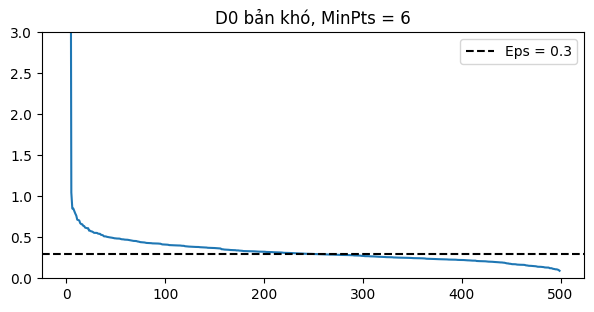

điểm có k-distance <= Eps: 260 / 500 (bản dễ: 474 / 500 )


In [56]:
## K-distance của D0 bản khó với Eps = 0.30 và MinPts = 6 (tham số của card_stream_hard)
p_hard = read_json(RAW + 'card_stream_hard/params.json')
zh0 = z_h[clean_h['is_d0'].to_numpy()]
kd_h = k_distance(zh0, p_hard['minpts'])
plt.figure(figsize=(7, 3.2)); plt.plot(np.sort(kd_h)[::-1]); plt.axhline(p_hard['eps'], color='k', ls='--', label=f"Eps = {p_hard['eps']}"); plt.ylim(0, 3); plt.legend(); plt.title('D0 bản khó, MinPts = 6'); plt.show()
print('điểm có k-distance <= Eps:', (kd_h <= p_hard['eps']).sum(), '/', len(kd_h), '(bản dễ:', (kd0 <= p_stream['eps']).sum(), '/', len(kd0), ')')

In [57]:
## Độ bền bản khó: fit trên D0 so với frozen_scaling của card_stream_hard (ARI, số lõi)
frozen_h = ManualScaler.from_dict({'method': 'standard', 'center': fs_h['mean'], 'scale': fs_h['std']})
m_h = clean_h['is_d0'].to_numpy()
lab_a, typ_a = fit_full_dbscan(scaler_h.transform(clean_h.loc[m_h, FEATURE_COLS]), p_hard['eps'], p_hard['minpts'])
lab_b, typ_b = fit_full_dbscan(frozen_h.transform(clean_h.loc[m_h, FEATURE_COLS]), p_hard['eps'], p_hard['minpts'])
r_h = compare_partitions(lab_a, lab_b, types_a=typ_a, types_b=typ_b)
print('số cụm', lab_a.max() + 1, 'và', lab_b.max() + 1, '| lõi', (typ_a == 3).sum(), 'và', (typ_b == 3).sum(), '| ARI =', round(r_h['ari'], 4), '| tập lõi giống nhau:', r_h['core_equal'])

số cụm 5 và 5 | lõi 260 và 240 | ARI = 0.8874 | tập lõi giống nhau: False


In [58]:
## Scorecard bản khó
truth_base_h = pd.read_csv('data/truth/card_txn_5d_hard_clean_base.csv'); truth_desc_h = pd.read_csv('data/truth/card_txn_5d_hard_clean_descriptive.csv')
sc_hard = score_cleaning('card_txn_5d_hard', raw_h, clean_h, truth_base_h, truth_desc_h, clean_hg, med_hg)
sc_hard[sc_hard['defect'] == 'missing_value'].drop(columns='table')

,defect,column,n,metric,value,global_median_error,gain_x,note
1,missing_value,amount_vnd,26,median_abs_error,1.832500e+05,2.880000e+05,1.571623,trung vị theo (kênh x nhóm hàng) -> kênh -> ch...
2,missing_value,amount_vnd,26,mean_abs_error,1.263942e+06,2.498885e+06,1.977056,trung vị theo (kênh x nhóm hàng) -> kênh -> ch...
3,missing_value,hour_of_day,28,median_abs_error,0.000000e+00,3.800000e+00,NaN,"sửa từ timestamp; cột chung = điền trung vị, k..."
4,missing_value,hour_of_day,28,mean_abs_error,0.000000e+00,4.613929e+00,NaN,"sửa từ timestamp; cột chung = điền trung vị, k..."
5,missing_value,distance_from_home_km,16,median_abs_error,1.727500e+00,3.715000e+00,2.150507,trung vị theo (kênh x nhóm hàng) -> kênh -> ch...
6,missing_value,distance_from_home_km,16,mean_abs_error,5.384375e+00,1.003438e+01,1.863610,trung vị theo (kênh x nhóm hàng) -> kênh -> ch...
7,missing_value,txns_last_7d,27,median_abs_error,1.000000e+00,3.000000e+00,3.000000,trung vị theo (kênh x nhóm hàng) -> kênh -> ch...
8,missing_value,txns_last_7d,27,mean_abs_error,1.500000e+00,2.777778e+00,1.851852,trung vị theo (kênh x nhóm hàng) -> kênh -> ch...
9,missing_value,merchant_risk_score,22,median_abs_error,1.800000e-02,9.150000e-02,5.083333,trung vị theo (kênh x nhóm hàng) -> kênh -> ch...
10,missing_value,merchant_risk_score,22,mean_abs_error,5.690909e-02,1.506364e-01,2.646965,trung vị theo (kênh x nhóm hàng) -> kênh -> ch...


In [59]:
## Ghi scorecard (cả hai bảng), bảng sạch và bảng chuẩn hóa của bản khó
pd.concat([sc_easy, sc_hard]).to_csv(OUT + 'cleaning_scorecard.csv', index=False, encoding='utf-8', lineterminator='\n')
clean_h.drop(columns=['timestamp']).rename(columns={'ts': 'timestamp_clean'}).to_csv(OUT + 'card_txn_5d_hard_clean.csv', index=False, encoding='utf-8', lineterminator='\n')
sc_h = pd.DataFrame(z_h, columns=[c + '_z' for c in FEATURE_COLS]); sc_h.insert(0, 'txn_id', clean_h['txn_id'].values)
sc_h.assign(segment_id=clean_h['segment_id'].values, is_d0=clean_h['is_d0'].values).to_csv(OUT + 'card_txn_5d_hard_scaled.csv', index=False, encoding='utf-8', lineterminator='\n')
print(len(sc_easy) + len(sc_hard), 'dòng scorecard |', len(clean_h), 'dòng bản khó')

38 dòng scorecard | 1592 dòng bản khó


In [60]:
## Ghi scaler_params.json cho cả hai bảng
params_out['card_txn_5d_hard'] = {'scaler': scaler_h.to_dict(), 'feature_columns': FEATURE_COLS, 'medians_d0': med_h,
    'd0_rule': '500 giao dịch sớm nhất theo timestamp', 'eps': p_hard['eps'], 'minpts': p_hard['minpts']}
Path(OUT + 'scaler_params.json').write_text(json.dumps(params_out, indent=2, ensure_ascii=False), encoding='utf-8', newline='\n')
print(sorted(params_out), '| ghi xong scaler_params.json')

['card_txn_5d', 'card_txn_5d_hard'] | ghi xong scaler_params.json


In [61]:
## Đọc lại scaler_params.json và dựng lại scaler: kết quả phải trùng
back = ManualScaler.from_dict(read_json(OUT + 'scaler_params.json')['card_txn_5d']['scaler'])
print('trùng khớp:', np.array_equal(back.transform(clean[FEATURE_COLS]), z))

trùng khớp: True
